# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


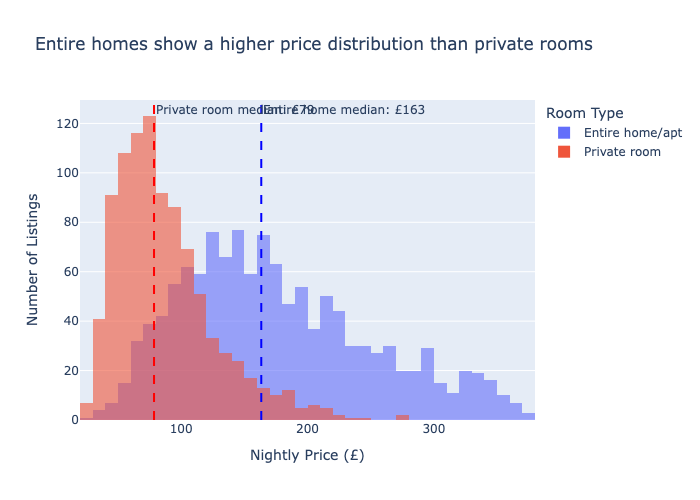

In [5]:
import sys

# Task 1

# Keep only the two required room types
# Cap extreme prices at the 95th percentile (as required)
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95].copy()

# Keep only the two required room types
hist_df = df_cap[
    df_cap['room_type'].isin(['Entire home/apt', 'Private room'])
].copy()

# Calculate median price for each room type
medians = hist_df.groupby('room_type')['price'].median()

# Create overlapping histogram
fig = px.histogram(
    hist_df,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=50,
    title='Entire homes show a higher price distribution than private rooms',
    labels={
        'price': 'Nightly Price (£)',
        'room_type': 'Room Type'
    }
)

# Add median reference lines
fig.add_vline(
    x=medians['Entire home/apt'],
    line_dash='dash',
    line_color='blue',
    annotation_text=f"Entire home median: £{medians['Entire home/apt']:.0f}"
)

fig.add_vline(
    x=medians['Private room'],
    line_dash='dash',
    line_color='red',
    annotation_text=f"Private room median: £{medians['Private room']:.0f}"
)

fig.update_layout(
    xaxis_title='Nightly Price (£)',
    yaxis_title='Number of Listings',
    legend_title='Room Type'
)

# Install the missing dependency required for Plotly notebook rendering
!{sys.executable} -m pip install "nbformat>=4.2.0"

# Show the figure after the dependency is available
fig.show(renderer="png")

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

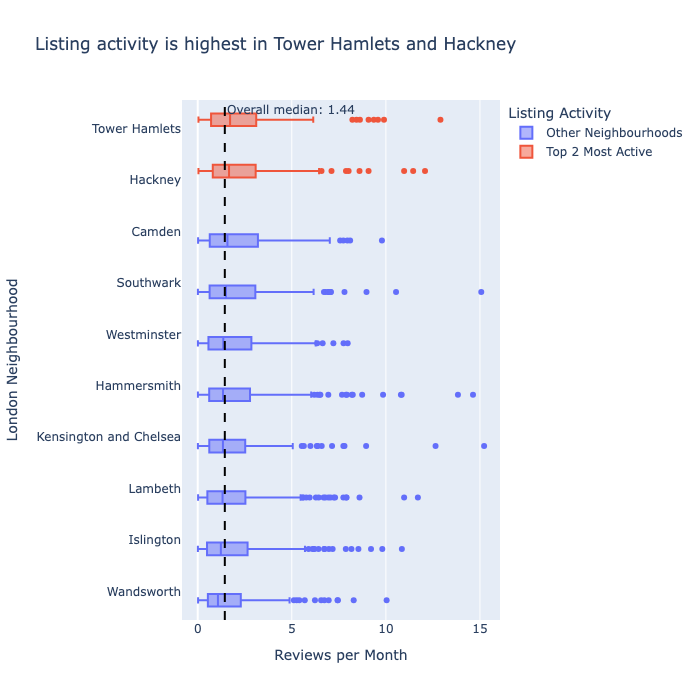

In [6]:
# Task 2
# Remove listings with zero reviews per month
box_df = df_cap[df_cap['reviews_per_month'] > 0].copy()

# Calculate median activity for each neighbourhood
borough_medians = (
    box_df.groupby('neighbourhood')['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

# Identify the two most active neighbourhoods
top_two = borough_medians.head(2).index.tolist()

# Highlight the two busiest neighbourhoods
box_df['Activity Group'] = np.where(
    box_df['neighbourhood'].isin(top_two),
    'Top 2 Most Active',
    'Other Neighbourhoods'
)

# Sort neighbourhoods by median activity
borough_order = borough_medians.index.tolist()

# Create horizontal box plot
fig = px.box(
    box_df,
    x='reviews_per_month',
    y='neighbourhood',
    orientation='h',
    color='Activity Group',
    category_orders={'neighbourhood': borough_order},
    points='outliers',
    title=f'Listing activity is highest in {top_two[0]} and {top_two[1]}',
    labels={
        'reviews_per_month': 'Reviews per Month',
        'neighbourhood': 'London Neighbourhood'
    }
)

# Add overall median reference line
overall_median = box_df['reviews_per_month'].median()

fig.add_vline(
    x=overall_median,
    line_dash='dash',
    line_color='black',
    annotation_text=f'Overall median: {overall_median:.2f}'
)

fig.update_layout(
    xaxis_title='Reviews per Month',
    yaxis_title='London Neighbourhood',
    height=max(700, len(borough_order) * 25),
    legend_title='Listing Activity'
)

fig.show(renderer="png")
